In [1]:
 !pip install tensorflow --user

Train shape: (60000, 28, 28)
Test shape:  (10000, 28, 28)


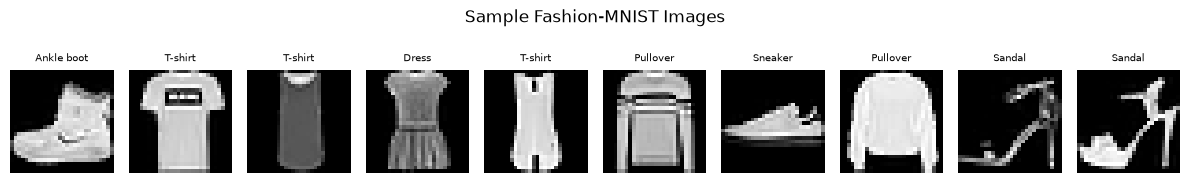

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize pixel values 0-255 → 0-1
X_train = X_train / 255.0
X_test  = X_test  / 255.0

print("Train shape:", X_train.shape)
print("Test shape: ", X_test.shape)

# One-hot encode labels
y_train_enc = to_categorical(y_train, 10)
y_test_enc  = to_categorical(y_test,  10)

class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress',    'Coat',
               'Sandal',  'Shirt',   'Sneaker',   'Bag', 'Ankle boot']

# Preview sample images
plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(class_names[y_train[i]], fontsize=7)
    plt.axis('off')
plt.suptitle("Sample Fashion-MNIST Images", fontsize=12)
plt.tight_layout()
plt.show()


In [3]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

# Flatten 28x28 = 784 pixels → ANN input
X_train_flat = X_train.reshape(-1, 784)
X_test_flat  = X_test.reshape(-1, 784)

ann = Sequential([
    Flatten(input_shape=(784,)),
    Dense(128, activation='relu'),
    Dense(64,  activation='relu'),
    Dense(10,  activation='softmax')
])

ann.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
ann.summary()

ann_history = ann.fit(
    X_train_flat, y_train_enc,
    epochs=10,
    batch_size=32,
    validation_data=(X_test_flat, y_test_enc),
    verbose=1
)

ann_loss, ann_acc = ann.evaluate(X_test_flat, y_test_enc, verbose=0)
print(f"\nANN Test Accuracy : {ann_acc:.4f}  ({ann_acc*100:.2f}%)")
print(f"ANN Test Loss     : {ann_loss:.4f}")


C:\Users\i5 74h\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - accuracy: 0.8246 - loss: 0.4955 - val_accuracy: 0.8490 - val_loss: 0.4190
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8663 - loss: 0.3677 - val_accuracy: 0.8570 - val_loss: 0.3867
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8766 - loss: 0.3347 - val_accuracy: 0.8610 - val_loss: 0.3839
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.8855 - loss: 0.3086 - val_accuracy: 0.8654 - val_loss: 0.3710
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - accuracy: 0.8906 - loss: 0.2922 - val_accuracy: 0.8674 - val_loss: 0.3757
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.8961 - loss: 0.2770 - val_accuracy: 0.8779 - val_loss: 0.3437
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.8995 - loss: 0.2677 - val_accuracy: 0.8781 - val_loss: 0.3369
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9028 - loss: 0

In [4]:

from tensorflow.keras.layers import Conv2D, MaxPooling2D

# CNN needs shape (28, 28, 1) — add channel dimension
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn  = X_test.reshape(-1, 28, 28, 1)

cnn = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10,  activation='softmax')
])

cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

cnn_history = cnn.fit(
    X_train_cnn, y_train_enc,
    epochs=10,
    batch_size=32,
    validation_data=(X_test_cnn, y_test_enc),
    verbose=1
)

cnn_loss, cnn_acc = cnn.evaluate(X_test_cnn, y_test_enc, verbose=0)
print(f"\nCNN Test Accuracy : {cnn_acc:.4f}  ({cnn_acc*100:.2f}%)")
print(f"CNN Test Loss     : {cnn_loss:.4f}")


C:\Users\i5 74h\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 43s 21ms/step - accuracy: 0.8343 - loss: 0.4551 - val_accuracy: 0.8724 - val_loss: 0.3570
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 39s 21ms/step - accuracy: 0.8874 - loss: 0.3053 - val_accuracy: 0.8972 - val_loss: 0.2903
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 42s 22ms/step - accuracy: 0.9049 - loss: 0.2572 - val_accuracy: 0.8947 - val_loss: 0.2851
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 40s 22ms/step - accuracy: 0.9161 - loss: 0.2249 - val_accuracy: 0.9045 - val_loss: 0.2638
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 43s 23ms/step - accuracy: 0.9263 - loss: 0.1968 - val_accuracy: 0.8912 - val_loss: 0.3021
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 22ms/step - accuracy: 0.9331 - loss: 0.1782 - val_accuracy: 0.9071 - val_loss: 0.2701
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 22ms/step - accuracy: 0.9404 - loss: 0.1570 - val_accuracy: 0.9067 - val_loss: 0.2758
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 42s 22ms/step - accuracy: 0.9466 -

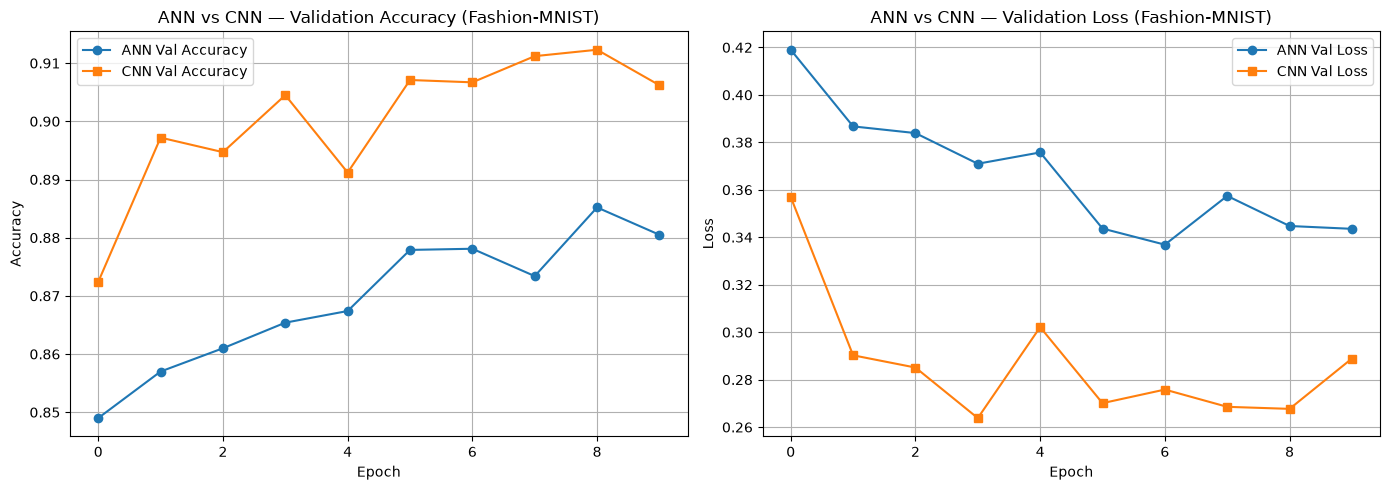

In [5]:

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(ann_history.history['val_accuracy'], label='ANN Val Accuracy', marker='o')
plt.plot(cnn_history.history['val_accuracy'], label='CNN Val Accuracy', marker='s')
plt.title('ANN vs CNN — Validation Accuracy (Fashion-MNIST)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(ann_history.history['val_loss'], label='ANN Val Loss', marker='o')
plt.plot(cnn_history.history['val_loss'], label='CNN Val Loss', marker='s')
plt.title('ANN vs CNN — Validation Loss (Fashion-MNIST)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


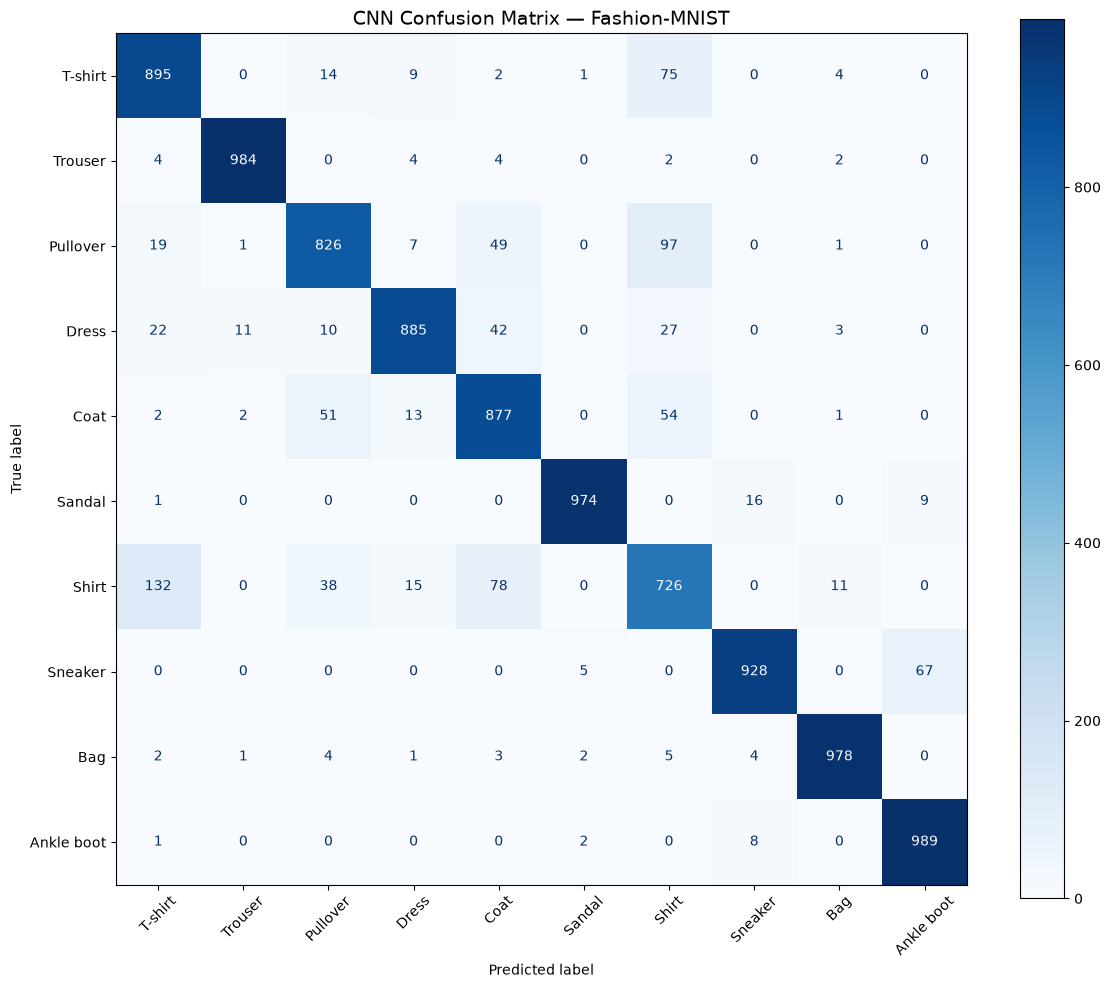


CNN Classification Report:
              precision    recall  f1-score   support

     T-shirt       0.83      0.90      0.86      1000
     Trouser       0.98      0.98      0.98      1000
    Pullover       0.88      0.83      0.85      1000
       Dress       0.95      0.89      0.92      1000
        Coat       0.83      0.88      0.85      1000
      Sandal       0.99      0.97      0.98      1000
       Shirt       0.74      0.73      0.73      1000
     Sneaker       0.97      0.93      0.95      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.93      0.99      0.96      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



In [6]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_pred_cnn = np.argmax(cnn.predict(X_test_cnn), axis=1)

cm = confusion_matrix(y_test, y_pred_cnn)
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, xticks_rotation=45, cmap='Blues')
plt.title("CNN Confusion Matrix — Fashion-MNIST", fontsize=14)
plt.tight_layout()
plt.show()

print("\nCNN Classification Report:")
print(classification_report(y_test, y_pred_cnn, target_names=class_names))


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


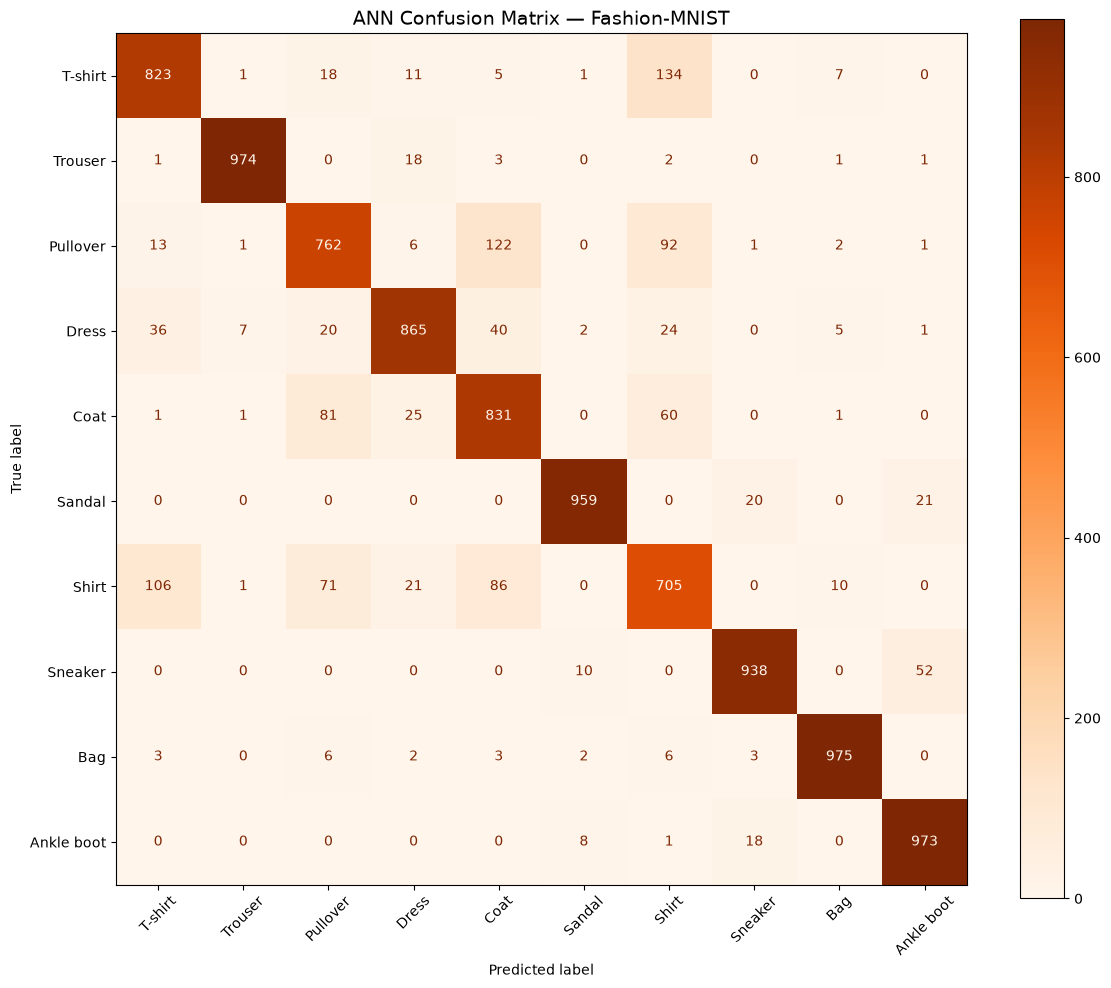


ANN Classification Report:
              precision    recall  f1-score   support

     T-shirt       0.84      0.82      0.83      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.80      0.76      0.78      1000
       Dress       0.91      0.86      0.89      1000
        Coat       0.76      0.83      0.80      1000
      Sandal       0.98      0.96      0.97      1000
       Shirt       0.69      0.70      0.70      1000
     Sneaker       0.96      0.94      0.95      1000
         Bag       0.97      0.97      0.97      1000
  Ankle boot       0.93      0.97      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



In [7]:

y_pred_ann = np.argmax(ann.predict(X_test_flat), axis=1)

cm_ann = confusion_matrix(y_test, y_pred_ann)
disp_ann = ConfusionMatrixDisplay(cm_ann, display_labels=class_names)
fig, ax = plt.subplots(figsize=(12, 10))
disp_ann.plot(ax=ax, xticks_rotation=45, cmap='Oranges')
plt.title("ANN Confusion Matrix — Fashion-MNIST", fontsize=14)
plt.tight_layout()
plt.show()

print("\nANN Classification Report:")
print(classification_report(y_test, y_pred_ann, target_names=class_names))


In [8]:

print("=" * 50)
print(f"{'Model':<10} {'Accuracy':>15} {'Loss':>12}")
print("=" * 50)
print(f"{'ANN':<10} {ann_acc:>15.4f} {ann_loss:>12.4f}")
print(f"{'CNN':<10} {cnn_acc:>15.4f} {cnn_loss:>12.4f}")
print("=" * 50)
print(f"CNN outperforms ANN by {(cnn_acc - ann_acc)*100:.2f}% accuracy")


Model             Accuracy         Loss
ANN                 0.8805       0.3436
CNN                 0.9062       0.2889
CNN outperforms ANN by 2.57% accuracy


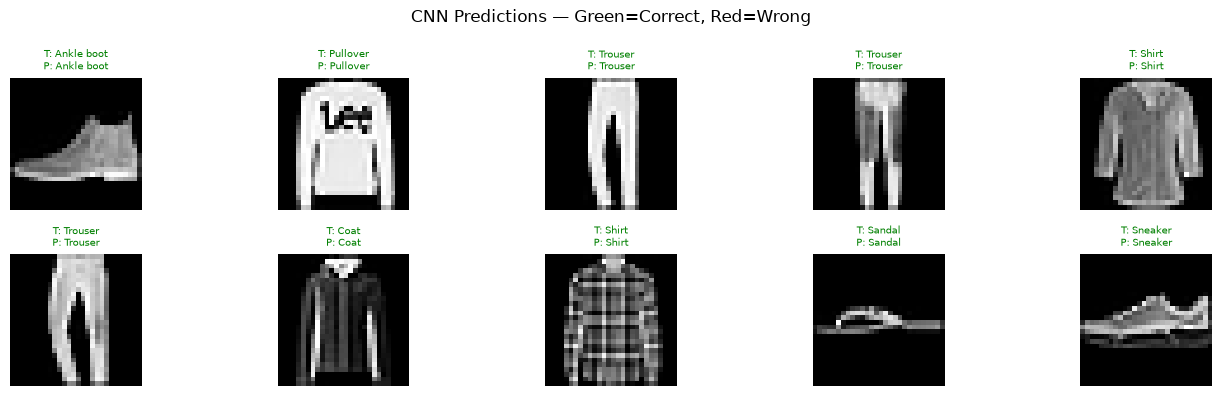

In [9]:

plt.figure(figsize=(14, 4))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_test[i], cmap='gray')
    true_label = class_names[y_test[i]]
    pred_label = class_names[y_pred_cnn[i]]
    color      = 'green' if true_label == pred_label else 'red'
    plt.title(f"T: {true_label}\nP: {pred_label}", fontsize=7, color=color)
    plt.axis('off')
plt.suptitle("CNN Predictions — Green=Correct, Red=Wrong", fontsize=12)
plt.tight_layout()
plt.show()